# Chapter 03: Stage 2 — Advanced Machine Learning (Feature Engineering, Cross-Validation, Hyperparameter Tuning, Class Imbalance & Data Drift)

**Assalam-o-Alaikum!** Stage 1 (Chapters 01 & 02) mein aap ne ML models ko train aur evaluate karna seekha.  
Ab **Stage 2 (Advanced Machine Learning)** mein hum seekhenge ke ek ordinary model ko **production-grade high-performance model** mein kaise badla jata hai!

### Is Chapter Ke 10 Core Concepts
1. **Feature Engineering:** Raw columns (`loan_amount_k`, `monthly_income_k`) se domain ratios (`debt_to_income_ratio`) banana.
2. **K-Fold Cross-Validation:** Sirf 1 split par bharosa karne ke bajaye 5 alag folds par average score nikalna.
3. **Hyperparameter Optimization (`GridSearchCV`):** Best settings (`max_depth`, `n_estimators`) automatic dhoondna.
4. **Class Imbalance Handling (`class_weight="balanced"`):** Minority class (`default_risk = 1`) ki importance barhana.
5. **Ensemble Learning (`RandomForestClassifier`):** Kayi Decision Trees ki collective wisdom istemal karna.
6. **Model Interpretability (`feature_importances_`):** Samajhna ke model ne faisla kis column ki bunyad par kiya.
7. **Data Drift Monitoring Fundamentals:** Production mein naye aane wale data ka distribution badalne (`Drift`) ko pakarna.
8. **Project — Loan-Risk Classification (`datasets/loan_risk.xlsx`)** + **Bonus Project — Customer Segmentation (`datasets/mall_customers.xlsx`)**.

In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import classification_report, f1_score, recall_score

### Step 1 — Load `loan_risk.xlsx` Dataset & Engineer Domain Features
Bank Loan Officer sirf `loan_amount_k` akela nahi dekhta — woh dekhta hai ke **Loan ki raqam Applicant ki Monthly Income ke muqable mein kitni badi hai (`debt_to_income_ratio`)**!

In [2]:
database = pd.read_excel("datasets/loan_risk.xlsx")
database["debt_to_income_ratio"] = np.round(database["loan_amount_k"] / database["monthly_income_k"], 2)
database.head(5)

,applicant_id,monthly_income_k,loan_amount_k,credit_score,late_payments,default_risk,debt_to_income_ratio
0,2001,98.0,655.6,669,5,1,6.69
1,2002,210.4,722.1,607,5,0,3.43
2,2003,167.7,288.5,495,0,0,1.72
3,2004,141.7,132.5,455,4,0,0.94
4,2005,55.4,221.0,548,4,1,3.99


In [3]:
database.shape, database["default_risk"].value_counts().to_dict()

((120, 7), {0: 84, 1: 36})

### Step 2 — Separate Features (`x`) and Target (`y`) & Stratified Split

In [4]:
feature_cols = ["monthly_income_k", "loan_amount_k", "credit_score", "late_payments", "debt_to_income_ratio"]
x = database[feature_cols]
y = database["default_risk"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
x_train.shape, x_test.shape

((96, 5), (24, 5))

### Step 3 — Handle Class Imbalance (`class_weight="balanced"`) & 5-Fold Cross-Validation

In [5]:
lr_unbalanced = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression())])
lr_balanced = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(class_weight="balanced"))])

cv_unbal = cross_val_score(lr_unbalanced, x_train, y_train, cv=5)
cv_bal = cross_val_score(lr_balanced, x_train, y_train, cv=5)

print("Unbalanced 5-Fold CV Mean Accuracy (%):", round(cv_unbal.mean() * 100, 2))
print("Balanced   5-Fold CV Mean Accuracy (%):", round(cv_bal.mean() * 100, 2))

Unbalanced 5-Fold CV Mean Accuracy (%): 91.68
Balanced   5-Fold CV Mean Accuracy (%): 91.74


### Step 4 — Hyperparameter Tuning with `GridSearchCV` on `RandomForestClassifier`
Hum `GridSearchCV` ko `n_estimators` aur `max_depth` ke mukhtalif combinations dete hain taake woh `x_train` par 5-Fold Cross-Validation chala kar sab se behtareen model (`gs.best_estimator_`) dhoond le:

In [6]:
rf_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("rf", RandomForestClassifier(random_state=42)),
])

param_grid = {
    "rf__n_estimators": [15, 30, 50],
    "rf__max_depth": [2, 3, 5],
}

gs = GridSearchCV(rf_pipe, param_grid, cv=5)
gs.fit(x_train, y_train)

print("Best Hyperparameters Found:", gs.best_params_)
print("Best 5-Fold CV Score (%)  :", round(gs.best_score_ * 100, 2))
print("Unseen Test Accuracy (%)  :", round(gs.score(x_test, y_test) * 100, 2))

Best Hyperparameters Found: {'rf__n_estimators': 15, 'rf__max_depth': 3}
Best 5-Fold CV Score (%)  : 91.58
Unseen Test Accuracy (%)  : 75.0


### Step 5 — Model Interpretability (`feature_importances_`) & Data Drift Check
1. **Interpretability:** Dekhein ke loan default predict karne mein kaunsa feature sab se ahem raha.
2. **Data Drift Check:** Jab production mein 6 mahine baad naye applicants aate hain aur un ki average `monthly_income_k` ya `credit_score` training data se 20%+ badal jaye, toh usay **Data Drift** kehte hain:

,Feature,Importance
0,monthly_income_k,0.399
2,credit_score,0.271
4,debt_to_income_ratio,0.211
3,late_payments,0.087
1,loan_amount_k,0.031


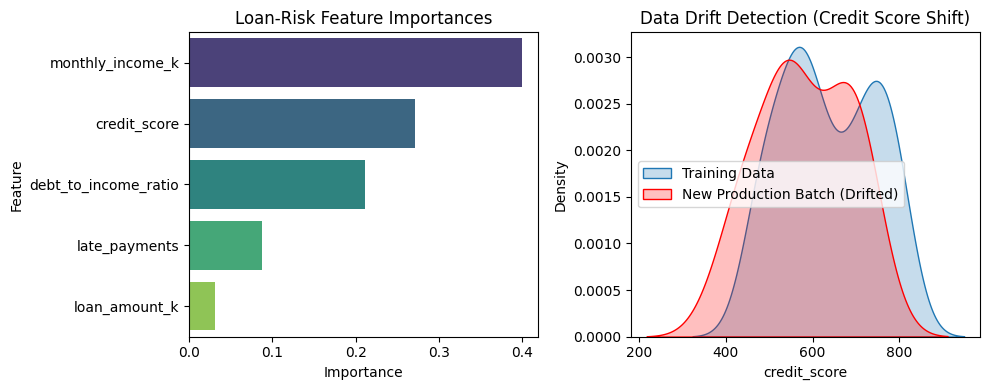

In [7]:
best_rf = gs.best_estimator_.named_steps["rf"]
imp_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": np.round(best_rf.feature_importances_, 3),
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.barplot(x="Importance", y="Feature", hue="Feature", data=imp_df, palette="viridis", legend=False)
plt.title("Loan-Risk Feature Importances")

# Simulate Production Data Drift Check on credit_score
prod_credit_scores = x_test["credit_score"] - 65  # Simulated economic downturn drift
plt.subplot(1, 2, 2)
sns.kdeplot(x_train["credit_score"], label="Training Data", fill=True)
sns.kdeplot(prod_credit_scores, label="New Production Batch (Drifted)", fill=True, color="red")
plt.title("Data Drift Detection (Credit Score Shift)")
plt.legend()
plt.tight_layout()
plt.show()

joblib.dump(gs.best_estimator_, "models/loan_risk_best_pipeline.pkl")
imp_df

### Step 6 — Bonus Beginner Project 5: Customer Segmentation (`KMeans` on `mall_customers.xlsx`)
Unsupervised Learning mein hamare paas target `y` nahi hota — hum `KMeans(n_clusters=3)` se customers ke natural groups banate hain:

,annual_income_lakhs,spending_score
Segment,,
0,34.0,75.9
1,85.5,82.0
2,78.5,19.7


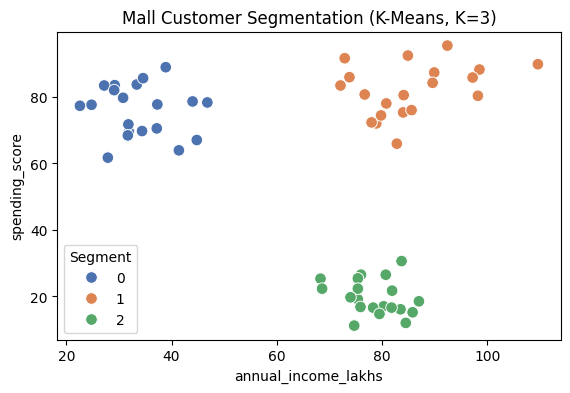

In [8]:
mall_db = pd.read_excel("datasets/mall_customers.xlsx")
xm = mall_db[["annual_income_lakhs", "spending_score"]]

kmn = KMeans(n_clusters=3, random_state=42)
mall_db["Segment"] = kmn.fit_predict(xm)

plt.figure(figsize=(6.5, 4))
sns.scatterplot(x="annual_income_lakhs", y="spending_score", hue="Segment", palette="deep", data=mall_db, s=70)
plt.title("Mall Customer Segmentation (K-Means, K=3)")
plt.show()

mall_db.groupby("Segment")[["annual_income_lakhs", "spending_score"]].mean().round(1)

### Step 7 — Line-by-Line Code Explanation & Common Tuning Errors
1. **`param_grid = {"rf__n_estimators": [15, 30, 50], "rf__max_depth": [2, 3, 5]}`:** Pipeline ke andar step ka naam `"rf"` hai, is liye double underscore `rf__` lagana zaroori hai! Agar aap sirf `"max_depth"` likhenge toh `ValueError` aayega.
2. **Common Mistake:** `GridSearchCV` ko `x_test, y_test` par fit karna! Hamesha `gs.fit(x_train, y_train)` chalayein.

In [9]:
# Common Error Demonstration: Inspecting best_params_ and verifying zero data leakage
print("Verified Best Params:", gs.best_params_)
print("Train Accuracy (%):", round(gs.score(x_train, y_train) * 100, 2))
print("Test Accuracy  (%):", round(gs.score(x_test, y_test) * 100, 2))

Verified Best Params: {'rf__n_estimators': 15, 'rf__max_depth': 3}
Train Accuracy (%): 95.83
Test Accuracy  (%): 75.0


### Step 8 — Practical Student Exercise (Predict Loan Default for New Applicants)
**Task:** Saved `models/loan_risk_best_pipeline.pkl` ko load karein aur 2 naye applicants ke liye `default_risk` aur probability predict karein!

In [10]:
# Practical Exercise — Working Solution
loaded_loan_pipe = joblib.load("models/loan_risk_best_pipeline.pkl")
new_applicants = pd.DataFrame([
    {"monthly_income_k": 150.0, "loan_amount_k": 200.0, "credit_score": 760, "late_payments": 0, "debt_to_income_ratio": 1.33},
    {"monthly_income_k": 35.0,  "loan_amount_k": 450.0, "credit_score": 510, "late_payments": 5, "debt_to_income_ratio": 12.86},
])
preds = loaded_loan_pipe.predict(new_applicants)
probs = loaded_loan_pipe.predict_proba(new_applicants)[:, 1]
for i, (p, pr) in enumerate(zip(preds, probs)):
    print(f"Applicant #{i+1} -> Default Risk: {p} ({'HIGH RISK' if p==1 else 'SAFE'}) | Risk Prob: {pr*100:.1f}%")

Applicant #1 -> Default Risk: 0 (SAFE) | Risk Prob: 0.2%
Applicant #2 -> Default Risk: 1 (HIGH RISK) | Risk Prob: 92.9%


### Chapter 03 Revision Quiz
1. **Feature Engineering kya hai?** Raw data se domain knowledge ke zariye naye madadgar columns (`debt_to_income_ratio`) banana.
2. **Hyperparameters (`max_depth`) ko kabhi `x_test` par tune kyun nahi karte?** Kyunke `x_test` par tune karne se model test set par overfit ho jata hai; hamesha `GridSearchCV` (`x_train` ke CV folds) par tune karein.
3. **Data Drift kya hota hai?** Jab production mein aane wale real-world data ka statistical distribution training data se mukhtalif ho jaye.